# Manual Day — Supervised Learning

Closed-agent, ~60 min. Complete every `# FILL IN` cell, then run the check.

**Three problems. Work in order, as many as time permits.** The last one is a challenge.

## Mini-lecture: supervised learning in PyTorch

### Supervised learning

You're handed pairs $(x_i, y_i)$, an input and the answer that goes with it. The
answers are the supervision. You want a function with $f(x_i) \approx y_i$, and not
just on those pairs: on inputs you've never seen, which is why MNIST ships a test set
that Problem 1 scores you on and never trains on. You pick a parametrized family of
functions, here a neural network, write a loss that says how wrong the current choice
is, and minimize it over the parameters.

What $y$ is splits the subject. In **classification** it's a label from a finite set:
which digit is this, is $q_1 q_2$ positive? In **regression** it's a number: what is
the invariant mass of this event? That decides your loss.

### What PyTorch gives you

In week 2 you wrote this loop in NumPy and differentiated by hand. Today is the same
loop, except PyTorch holds the parameters and computes the gradients, so your time
goes into the model instead of the chain rule.

A `torch.Tensor` is a NumPy array that can carry a gradient:
`torch.tensor(data, dtype=...)`. Inputs are `torch.float32`, class labels are
`torch.long`, and labels are plain integers rather than one-hot vectors.

`torch.nn.Sequential(a, b, c)` runs `a`, then `b`, then `c`. The workhorse is
`torch.nn.Linear(n_in, n_out)`, which computes $xW^T + b$ and owns its $W$ and $b$.
Activations go between: `torch.nn.ReLU()`, `torch.nn.Tanh()`, `torch.nn.Sigmoid()`.
Leave them out and the stack collapses to one linear map, however many layers you pile
up. `model(x)` runs the forward pass, taking `(N, n_in)` to `(N, n_out)`.

### Which loss

Two classes: `torch.nn.BCELoss()`, binary cross entropy,

$$L = -\frac{1}{N}\sum_i \Big[\, y_i \ln \hat{y}_i + (1-y_i)\ln(1-\hat{y}_i) \,\Big].$$

One term survives per sample. With $y_i = 1$ you're charged $-\ln \hat{y}_i$, zero
when the model says 1 and unbounded as it heads to 0. So the output has to be a
probability, which is why both networks in Problem 3 end in a `Sigmoid`.

More than two: `torch.nn.CrossEntropyLoss()`, the same idea with one term per class.
It wants raw scores, with no Softmax at the end of your model, because it applies its
own. An untrained model spreads probability evenly over $k$ classes, so the loss
starts at $\ln k$. If epoch 0 isn't near $\ln k$, something is already wrong.

Regression: `torch.nn.MSELoss()`, the mean squared error from week 2. Problem 2 uses
it.

### The loop

`torch.optim.Adam(model.parameters(), lr=0.01)`. That `model.parameters()` is how the
optimizer knows what it's allowed to move. Adam tunes a step size per parameter and is
the one I reach for by default. `torch.optim.SGD` is the plain version from week 2.

Four steps, in order:

1. **Clear** the previous step's gradients, `optimizer.zero_grad()`. PyTorch *adds*
   new gradients to whatever is sitting there, so skipping this sums every step you
   have taken, with no error. The symptom is a loss that climbs, or goes to `nan`.
2. **Forward and score**, `loss = criterion(model(x), y)`.
3. **Backward**, `loss.backward()`, which fills in a `.grad` on every parameter.
4. **Step** downhill, `optimizer.step()`.

```python
for epoch in range(num_epochs):
    optimizer.zero_grad()
    loss = criterion(model(x), y)
    loss.backward()
    optimizer.step()
```

Three more things that will bite you. `.item()` pulls a Python float out of a
one-element tensor, and appending the tensor instead keeps the whole graph alive, so
your memory grows every epoch. Wrap evaluation in `with torch.no_grad():`. And most
PyTorch errors are shape errors, so when you hit one, print `x.shape` and compare it
against the layer's `in_features`.

Problem 1 steps once per epoch on all 60,000 images at once. Problem 3 steps once per
sample, 121 times an epoch. Same four lines, different amount of data per step.

In [2]:
# GIVEN: imports
import torch
import numpy as np
import matplotlib.pyplot as plt

In [3]:
%pip install torchvision

Note: you may need to restart the kernel to use updated packages.


## Problem 1 — Build the network

MNIST: 60,000 training images of hand-written digits and 10,000 test images, 28x28 in
grayscale. Flattened, each one is 784 numbers, labeled 0 through 9. The test set is
the one you are scored on, and the network never trains on it.

Build the classifier with `torch.nn.Sequential`. The structure I want:

1. `torch.nn.Linear` from 784 inputs to 64,
2. `torch.nn.ReLU()`,
3. `torch.nn.Linear` from 64 to 10.

Ten outputs, one score per digit, and no Softmax at the end since `CrossEntropyLoss`
applies its own. Then write the training loop underneath, the four steps from the
mini-lecture. Data, loss and optimizer are given, and this loop steps on all 60,000
images at once.

**Known answer.** An untrained ten-class model is guessing, so the loss starts at
$\ln 10 \approx 2.303$, and the strip of test images printed under your model should
come out mostly red. Two hundred epochs take the loss below 0.1 and test accuracy to
about 97%, in a couple of seconds. The check looks at the layer shapes first, then
wants better than 90% on the test set.

train: (60000, 784) (60000,)   test: (10000, 784) (10000,)


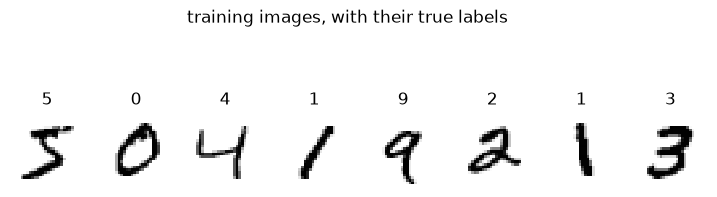

In [4]:
# GIVEN: MNIST, 28x28 grayscale hand-written digits. The first run downloads
# about 10 MB into ./data and caches it there; later runs read it off disk.
import torchvision

train_set = torchvision.datasets.MNIST(root="./data", train=True, download=True)
test_set = torchvision.datasets.MNIST(root="./data", train=False, download=True)

x_train = (train_set.data.float() / 255.0).reshape(-1, 784)   # (60000, 784), 0..1
y_train = train_set.targets                                   # (60000,), the digit 0..9
x_test = (test_set.data.float() / 255.0).reshape(-1, 784)     # (10000, 784)
y_test = test_set.targets
print("train:", tuple(x_train.shape), tuple(y_train.shape),
      "  test:", tuple(x_test.shape), tuple(y_test.shape))


def show_predictions(model, title, n=10):
    """Ten test images, labeled with whatever the network currently says."""
    with torch.no_grad():
        pred = model(x_test).argmax(1)
    acc = (pred == y_test).float().mean().item()
    fig, axes = plt.subplots(1, n, figsize=(1.1 * n, 1.7))
    for k, ax in enumerate(axes):
        ax.imshow(x_test[k].reshape(28, 28), cmap="gray_r", interpolation="nearest")
        ax.set_title(int(pred[k]), color="k" if int(pred[k]) == int(y_test[k]) else "r")
        ax.axis("off")
    plt.suptitle(f"{title}: {100 * acc:.1f}% of the test set right (red = wrong)", y=1.32)
    plt.show()


fig, axes = plt.subplots(1, 8, figsize=(9, 1.7))
for k, ax in enumerate(axes):
    ax.imshow(x_train[k].reshape(28, 28), cmap="gray_r", interpolation="nearest")
    ax.set_title(int(y_train[k]))
    ax.axis("off")
plt.suptitle("training images, with their true labels", y=1.32)
plt.show()

Sequential(
  (0): Linear(in_features=784, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=10, bias=True)
)


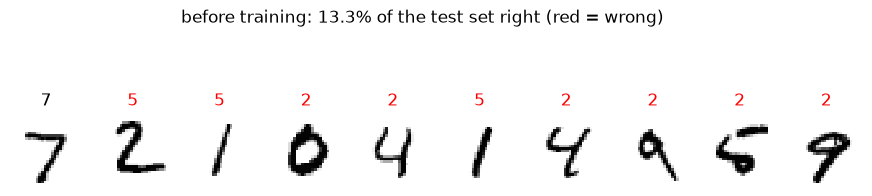

In [5]:
# FILL IN: the network. Three layers inside Sequential, as described above.
torch.manual_seed(0)       # GIVEN: same initialization for everyone
model = torch.nn.Sequential(
    # FILL IN: a linear layer taking the 784 pixels down to 64,
    # FILL IN: a nonlinearity,
    # FILL IN: a linear layer from 64 down to one score per digit,
    torch.nn.Linear(784, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 10)
)
print(model)

# GIVEN: what the network says before it has learned anything.
show_predictions(model, "before training")

In [6]:
# GIVEN: the loss and the optimizer.
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# FILL IN: the four lines of the loop, in the order the mini-lecture gives them.
# This one steps on all the training images at once, so the whole of `x_train` goes
# in and the whole of `y_train` is what you compare against.
losses = []
for epoch in range(200):
    # FILL IN: clear the gradients left over from the last step
    # FILL IN: run the model on x_train and score it against y_train, into `loss`
    # FILL IN: push the gradients back through the network
    # FILL IN: take the step downhill
    optimizer.zero_grad()
    loss = criterion(model(x_train), y_train)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 50 == 0:
        print(f"epoch {epoch:3d}: loss = {losses[-1]:.4f}")
print(f"epoch 200: loss = {losses[-1]:.4f}")

epoch   0: loss = 2.2933
epoch  50: loss = 0.2023
epoch 100: loss = 0.1173
epoch 150: loss = 0.0793
epoch 200: loss = 0.0565


loss: 2.293 -> 0.0565     (guessing is ln 10 = 2.303)
train accuracy: 98.4%     test accuracy: 96.8%
PASS: the network learned the digits.


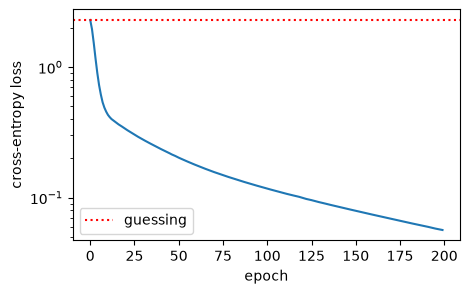

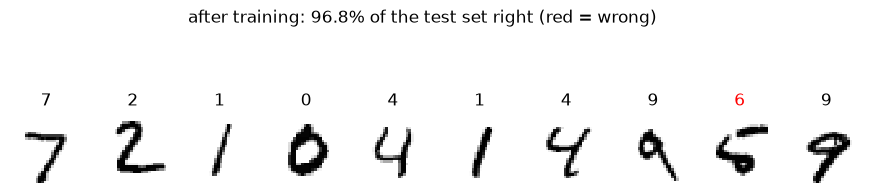

In [7]:
# CHECK (given): the structure first, then accuracy on data the network never saw.
assert isinstance(model, torch.nn.Sequential), "model should be a torch.nn.Sequential"
assert len(model) == 3, f"expected 3 layers, got {len(model)}"
assert isinstance(model[0], torch.nn.Linear), "layer 1 should be a Linear"
assert (model[0].in_features, model[0].out_features) == (784, 64),     f"layer 1 should be Linear(784, 64), got Linear({model[0].in_features}, {model[0].out_features})"
assert not isinstance(model[1], torch.nn.Linear), "layer 2 should be an activation, not a Linear"
assert isinstance(model[2], torch.nn.Linear), "layer 3 should be a Linear"
assert (model[2].in_features, model[2].out_features) == (64, 10),     f"layer 3 should be Linear(64, 10), got Linear({model[2].in_features}, {model[2].out_features})"
assert len(losses) == 200, f"the training loop should record 200 losses, got {len(losses)}"

with torch.no_grad():
    train_acc = (model(x_train).argmax(1) == y_train).float().mean().item()
    test_acc = (model(x_test).argmax(1) == y_test).float().mean().item()

print(f"loss: {losses[0]:.3f} -> {losses[-1]:.4f}     (guessing is ln 10 = {np.log(10):.3f})")
print(f"train accuracy: {100 * train_acc:.1f}%     test accuracy: {100 * test_acc:.1f}%")
assert losses[-1] < 0.15, f"training loss stalled at {losses[-1]:.4f}"
assert test_acc > 0.90, f"test accuracy {100 * test_acc:.1f}% is below 90%"
print("PASS: the network learned the digits.")

plt.figure(figsize=(5, 3))
plt.semilogy(losses)
plt.axhline(np.log(10), ls=":", c="r", label="guessing")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.legend()
plt.show()

show_predictions(model, "after training")

## Problem 2 — Invariant mass, and the variables to learn it from

Each row of `zee_data` is a $Z \to e^+e^-$ candidate: two electrons with transverse
momenta `pt1, pt2`, pseudorapidities `eta1, eta2`, and azimuthal angles `phi1, phi2`.
The invariant mass of the pair is

$$M = \sqrt{2\,p_{T,1}\,p_{T,2}\,\big(\cosh(\eta_1-\eta_2) - \cos(\phi_1-\phi_2)\big)}.$$

Reconstruct it first. Fill in `get_invariant_mass(...)` with vectorized NumPy, working
on whole columns rather than looping over rows, and build the 1-D array `masses`.

**Known answer.** The masses pile up at the $Z$ resonance, so the histogram peaks near
91 GeV. The check takes the modal bin and wants it inside [88, 94].

In [8]:
# GIVEN: Z -> e+ e- candidates from CERN OpenData (opendata.cern.ch/record/545).
# One row per event; columns include pt1, eta1, phi1 and pt2, eta2, phi2.
import pandas as pd
zee_data = pd.read_csv('Zee.csv')
pt1, pt2   = zee_data['pt1'].values,  zee_data['pt2'].values
eta1, eta2 = zee_data['eta1'].values, zee_data['eta2'].values
phi1, phi2 = zee_data['phi1'].values, zee_data['phi2'].values
print("events:", len(zee_data), " kinematic columns:", ['pt1','eta1','phi1','pt2','eta2','phi2'])

events: 10000  kinematic columns: ['pt1', 'eta1', 'phi1', 'pt2', 'eta2', 'phi2']


In [9]:
# FILL IN: the invariant mass, from the formula above.
def get_invariant_mass(pt1, pt2, eta1, eta2, phi1, phi2):
    # FILL IN: return M for whole columns at once, rather than one event at a time
    M = np.sqrt(2 * pt1 * pt2 * (np.cosh(eta1 - eta2) - np.cos(phi1 - phi2)))
    return M 

# FILL IN: apply it to every event, giving a 1-D array of masses
masses = get_invariant_mass(pt1, pt2, eta1, eta2, phi1, phi2)
print("computed", None if masses is None else len(masses), "invariant masses")

computed 10000 invariant masses


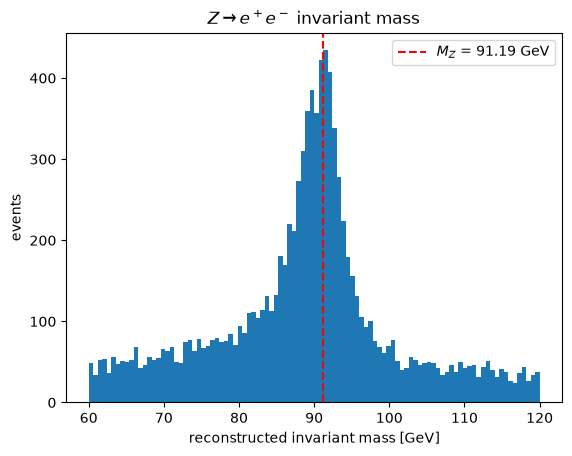

Modal (peak) bin center: 91.50 GeV
PASS: the invariant-mass spectrum peaks at the Z resonance.


In [10]:
# CHECK (given): histogram the reconstructed masses; the spectrum should peak
# at the Z-boson resonance M_Z ~ 91 GeV.
masses = np.asarray(masses, dtype=float)
masses = masses[np.isfinite(masses)]
counts, edges = np.histogram(masses, bins=100, range=(60, 120))
centers = 0.5 * (edges[:-1] + edges[1:])
peak = centers[np.argmax(counts)]

plt.figure()
plt.hist(masses, bins=100, range=(60, 120))
plt.axvline(91.19, color='r', ls='--', label='$M_Z$ = 91.19 GeV')
plt.xlabel("reconstructed invariant mass [GeV]"); plt.ylabel("events")
plt.title("$Z \\to e^+e^-$ invariant mass"); plt.legend(); plt.show()

print(f"Modal (peak) bin center: {peak:.2f} GeV")
assert 88.0 <= peak <= 94.0, f"peak {peak:.2f} GeV is not near M_Z"
print("PASS: the invariant-mass spectrum peaks at the Z resonance.")

### Now learn it with a network

Hand the same problem to a network: from the kinematics, predict the mass. You know
the exact answer, so you can measure how close it gets instead of guessing.

The network is the same in all three runs, and so is its initialization:
`100 -> ReLU -> 100 -> ReLU -> 1`, mean squared error, SGD, 20 epochs, one event per
step. Nothing at the end, since the output is a mass rather than a probability. The
only thing that changes is what you feed it.

Each run hands `train_regressor` an array with one row per event and one column per
input. `np.column_stack([a, b, c])` is how you build that: give it a list of columns
and it sets them side by side, so `np.column_stack([pt1, pt2])` has shape
`(10000, 2)`.

1. **No normalization.** The six raw columns in, the mass in GeV out, learning rate
   0.0001.
2. **Put everything on one scale.** The same six columns, but bring `pt1`, `pt2` and
   the target to order 1 by dividing each of them by 100, and raise the learning rate
   to 0.01.
3. **Use the variables the formula actually uses.** The six inputs enter it only
   through three combinations: one pairs up the two momenta, and the other two are
   differences, since the formula never sees $\eta_1$ or $\phi_1$ on its own, only how
   far apart the two electrons are. Take the magnitude of each difference, with
   `np.abs`. The formula is even in both, so the sign carries no information, and
   handing it over anyway makes the network spend capacity rediscovering a symmetry
   you could have imposed for free. Then bring the three to order 1 the same way: the
   momentum combination carries two factors of $p_T$, so divide it by 100 x 100, and
   the target again by 100.

**Known answers.** Run 1 lands at about 12.1 GeV. The spread of the masses is 12.13,
so it learned to output the average and stopped there: the momenta run past a hundred
GeV while the etas and phis are order 1, and no single learning rate suits both. Run 2
reaches roughly 3 GeV, which is what the scaling alone buys. Run 3 gets to about
0.9 GeV on a 91 GeV object, with half as many inputs. Twenty seconds per run.

**What the plots at the end show.** You get one scatter plot per run. Each dot is a
single event, placed at its true mass across and at the mass the network predicted for
it up, and the red dashed line marks where every dot would sit if the network were
exactly right. Run 1 comes out as a flat horizontal line at about 89 GeV, which is
what a network that ignores its input and reports the average every time looks like;
runs 2 and 3 lie along the diagonal, the first as a loose cloud and the second as a
tight band.

In [11]:
# GIVEN: one training run. Same architecture, same initialization, and 20 epochs of
# the loop you write in Problem 3. The only thing that varies between runs is the
# data you hand it.
def train_regressor(x, y, lr, epochs=20, seed=0):
    if x is None or y is None:
        raise ValueError("fill in x and y for this attempt before training")
    x = torch.tensor(np.asarray(x), dtype=torch.float32)
    y = torch.tensor(np.asarray(y).reshape(-1, 1), dtype=torch.float32)
    torch.manual_seed(seed)
    net = torch.nn.Sequential(
        torch.nn.Linear(x.shape[1], 100), torch.nn.ReLU(),
        torch.nn.Linear(100, 100), torch.nn.ReLU(),
        torch.nn.Linear(100, 1),
    )
    optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    criterion = torch.nn.MSELoss()
    for epoch in range(epochs):
        total = 0.0
        for i in range(len(x)):
            optimizer.zero_grad()
            loss = criterion(net(x[i]), y[i])
            loss.backward()
            optimizer.step()
            total += loss.item()
        if epoch % 5 == 0 or epoch == epochs - 1:
            print(f"   epoch {epoch:2d}: mean squared error = {total / len(x):.5f}")
    with torch.no_grad():
        return net(x).numpy().ravel()


def rms_error(pred, scale=1.0):
    """RMS error in GeV. `scale` undoes whatever scaling you applied to the target."""
    return float(np.sqrt(np.mean((scale * pred - masses) ** 2)))

In [12]:
# FILL IN (1): the six raw columns, the mass in GeV, nothing scaled or combined.
x_raw = np.column_stack([pt1, pt2, eta1, eta2, phi1, phi2])      # FILL IN: shape (10000, 6)
y_raw = masses      # FILL IN: the target, in GeV

pred_raw = train_regressor(x_raw, y_raw, lr=0.0001)
rms_raw = rms_error(pred_raw)
print(f"1. no normalization:        RMS error {rms_raw:.2f} GeV")

   epoch  0: mean squared error = 390.32077
   epoch  5: mean squared error = 149.38458
   epoch 10: mean squared error = 149.37520
   epoch 15: mean squared error = 149.36808
   epoch 19: mean squared error = 149.36332
1. no normalization:        RMS error 12.16 GeV


In [13]:
# FILL IN (2): the same six columns, with the momenta and the target brought to order 1.
x_scaled = np.column_stack([pt1 / 100, pt2 / 100, eta1, eta2, phi1, phi2])   # FILL IN: shape (10000, 6)
y_scaled = y_raw / 100   # FILL IN: the target, put on that same scale

pred_scaled = train_regressor(x_scaled, y_scaled, lr=0.01)
rms_scaled = rms_error(pred_scaled, scale=100)
print(f"2. scaled, six inputs:      RMS error {rms_scaled:.2f} GeV")

   epoch  0: mean squared error = 0.01221
   epoch  5: mean squared error = 0.00239
   epoch 10: mean squared error = 0.00166
   epoch 15: mean squared error = 0.00117
   epoch 19: mean squared error = 0.00087
2. scaled, six inputs:      RMS error 2.95 GeV


In [17]:
# FILL IN (3): the three combinations the formula depends on, with run 2's scaling.
x_phys = np.column_stack([pt1 * pt2 / 1000, eta1 - eta2, phi1 - phi2])     # FILL IN: shape (10000, 3)
y_phys = y_scaled     # FILL IN: the target, on the same scale as run 2

pred_phys = train_regressor(x_phys, y_phys, lr=0.01)
rms_phys = rms_error(pred_phys, scale=100)
print(f"3. three physics variables: RMS error {rms_phys:.2f} GeV")

   epoch  0: mean squared error = 0.00495
   epoch  5: mean squared error = 0.00150
   epoch 10: mean squared error = 0.00060
   epoch 15: mean squared error = 0.00027
   epoch 19: mean squared error = 0.00020
3. three physics variables: RMS error 1.30 GeV


spread of the masses:        12.13 GeV   (always predict the average)
1. no normalization:         12.16 GeV
2. scaled, six inputs:        2.95 GeV
3. three physics variables:   1.30 GeV

PASS: scaling the inputs helped, and choosing the inputs helped more.


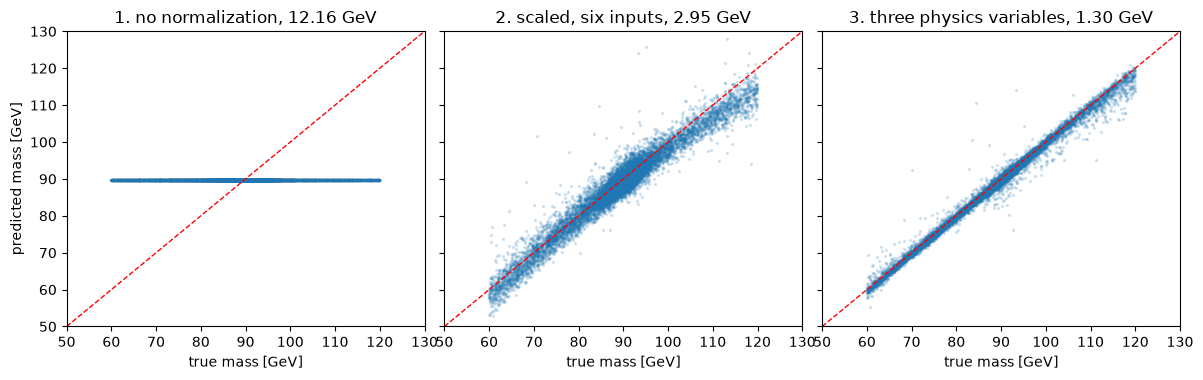

In [18]:
# CHECK (given): all three runs side by side, in GeV.
spread = float(masses.std())
print(f"spread of the masses:       {spread:6.2f} GeV   (always predict the average)")
print(f"1. no normalization:        {rms_raw:6.2f} GeV")
print(f"2. scaled, six inputs:      {rms_scaled:6.2f} GeV")
print(f"3. three physics variables: {rms_phys:6.2f} GeV")
print()

assert np.shape(x_raw) == (len(masses), 6), f"x_raw should be (10000, 6), got {np.shape(x_raw)}"
assert np.shape(x_scaled) == (len(masses), 6), f"x_scaled should be (10000, 6), got {np.shape(x_scaled)}"
assert np.shape(x_phys) == (len(masses), 3), f"x_phys should be (10000, 3), got {np.shape(x_phys)}"
assert abs(rms_raw - spread) < 1.0, f"run 1 should land near the spread {spread:.2f} GeV, got {rms_raw:.2f}"
assert rms_scaled < 5.0, f"run 2 should reach a few GeV, got {rms_scaled:.2f}"
assert rms_phys < 1.5, f"run 3 should reach about 1 GeV, got {rms_phys:.2f}"
assert rms_phys < rms_scaled < rms_raw, "the three runs should improve in that order"
print("PASS: scaling the inputs helped, and choosing the inputs helped more.")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), sharex=True, sharey=True)
runs = [("1. no normalization", pred_raw, 1, rms_raw),
        ("2. scaled, six inputs", pred_scaled, 100, rms_scaled),
        ("3. three physics variables", pred_phys, 100, rms_phys)]
for ax, (name, pred, scale, r) in zip(axes, runs):
    ax.scatter(masses, scale * pred, s=2, alpha=0.15)
    ax.plot([50, 130], [50, 130], "r--", lw=1)
    ax.set_xlim(50, 130)
    ax.set_ylim(50, 130)
    ax.set_title(f"{name}, {r:.2f} GeV")
    ax.set_xlabel("true mass [GeV]")
axes[0].set_ylabel("predicted mass [GeV]")
plt.tight_layout()
plt.show()

## Problem 3 — Challenge: a classifier no straight line can build

Two charges, $q_1$ and $q_2$, each an integer from -5 to 5. The label is 1 when the
pair repels, which is when $q_1 q_2 > 0$. Every pair on that grid is one training
example, 121 in all, and 50 of them repel, so a model that gives up and calls
everything 0 already scores 58.7%. (A charge of zero feels nothing, so that row and
column are labeled 0 as well.)

The catch is that two charges repel in two unrelated ways: both positive, or both
negative. On the $(q_1, q_2)$ plane those are opposite corners, the upper right and
the lower left, with the attracting pairs filling the other two. This is XOR. Any
straight line you draw catches one repelling corner and gives up the other, so 58.7%
is the ceiling for a line. Hidden layers are what let the boundary bend.

Build two models and train both.

1. `train(model, n_epochs=100, lr=0.01)`, the per-sample loop: the four steps from
   Problem 1, but stepping on one grid point at a time and summing the losses over an
   epoch. Build the optimizer inside, since it needs the parameters of whichever model
   it is handed.
2. `linear_model`, no hidden layer at all: one `torch.nn.Linear` from 2 to 1, then
   `torch.nn.Sigmoid()`.
3. `deep_model`: `Linear` 2 to 10, `Tanh`, `Linear` 10 to 10, `Tanh`, `Linear` 10 to
   1, `Sigmoid`.

Both end in a `Sigmoid` because `BCELoss` wants a probability. One thing to expect:
the loss printed here is a sum over all 121 points, not an average like Problem 1's,
so it sits in the tens instead of near zero. That is the scale, not a bug.

**Known answers.** The linear model gets 58.7%, its summed loss settling at 78.87
wherever it starts, because there is one best line and it finds it. The deep model
gets 100%, with a loss near 1. The check draws both decision regions: one flat
half-plane, and four correct quadrants.

In [19]:
# GIVEN: charge-sign data on the (q1, q2) integer grid.
# Label is 1 if the product q1*q2 > 0, else 0 (self-contained, no CSV).
def f(q1, q2):
    return int(q1 * q2 > 0)

x, y = [], []
for q1 in range(-5, 6):
    for q2 in range(-5, 6):
        x.append([q1, q2])
        y.append([f(q1, q2)])

x = torch.tensor(x, dtype=torch.float32)   # shape (121, 2)
y = torch.tensor(y, dtype=torch.float32)   # shape (121, 1)


def accuracy(model):
    """Fraction of the grid the model gets right."""
    with torch.no_grad():
        return ((model(x) > 0.5).float() == y).float().mean().item()


baseline = 1 - y.mean().item()
print("x:", tuple(x.shape), " y:", tuple(y.shape))
print(f"label 1 on {int(y.sum())} of {len(y)} points, so always guessing 0 scores {100 * baseline:.1f}%")

x: (121, 2)  y: (121, 1)
label 1 on 50 of 121 points, so always guessing 0 scores 58.7%


In [20]:
# FILL IN: the per-sample training loop, wrapped in a function so you can run it on
# two different models. Note what has to be built inside it.
def train(model, n_epochs=100, lr=0.01):
    criterion = torch.nn.BCELoss()
    # FILL IN: the optimizer, over the parameters of the model it was handed
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    losses = []
    for epoch in range(n_epochs):
        epoch_loss = 0.0
        for i in range(len(x)):
            # FILL IN: clear the gradients left over from the previous point
            # FILL IN: predict on grid point i, and score that against label i
            # FILL IN: push the gradients back, then take the step
            # FILL IN: add this point's loss to the running total for the epoch
            optimizer.zero_grad()
            output = model(x[i])
            loss = criterion(output, y[i])
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        losses.append(epoch_loss)
    return losses

In [21]:
# FILL IN: the model with no hidden layer, then train it.
torch.manual_seed(0)       # GIVEN: same initialization for everyone
linear_model = torch.nn.Sequential(
    # FILL IN: one linear layer, 2 inputs to 1 output,
    # FILL IN: then a sigmoid, so the output is a probability
    torch.nn.Linear(2, 1),
    torch.nn.Sigmoid()
)
lin_losses = train(linear_model)
lin_acc = accuracy(linear_model)
print(f"linear:  accuracy {100 * lin_acc:.1f}%   loss {lin_losses[0]:.2f} -> {lin_losses[-1]:.2f}")

linear:  accuracy 58.7%   loss 79.49 -> 78.87


In [24]:
# FILL IN: the model with two hidden layers, then train it.
torch.manual_seed(0)       # GIVEN: same initialization for everyone
deep_model = torch.nn.Sequential(
    # FILL IN: 2 inputs up to 10, then a tanh,
    # FILL IN: 10 to 10, then a tanh,
    # FILL IN: 10 down to 1, then a sigmoid
    torch.nn.Linear(2, 10), torch.nn.Tanh(),
    torch.nn.Linear(10, 10), torch.nn.Tanh(),
    torch.nn.Linear(10, 1), torch.nn.Sigmoid()
)
deep_losses = train(deep_model)
deep_acc = accuracy(deep_model)
print(f"deep:    accuracy {100 * deep_acc:.1f}%   loss {deep_losses[0]:.2f} -> {deep_losses[-1]:.2f}")

deep:    accuracy 100.0%   loss 82.67 -> 1.11


always guessing 0:   58.7%
linear model:        58.7%
deep model:          100.0%

PASS: the line can't do it, and the hidden layers can.


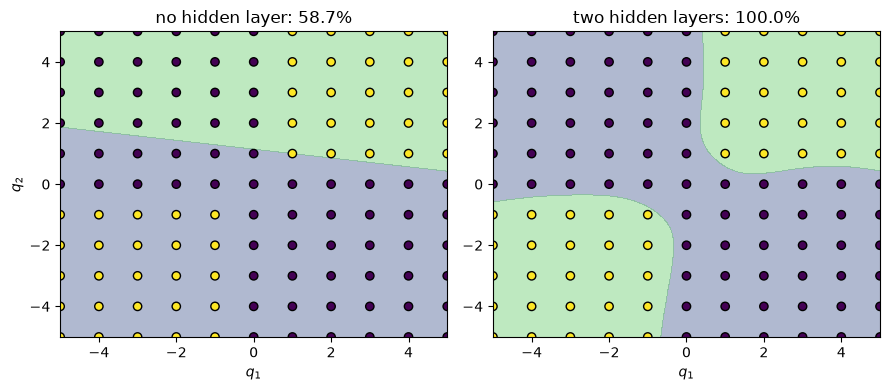

In [25]:
# CHECK (given): the two models side by side on the same grid.
print(f"always guessing 0:   {100 * baseline:.1f}%")
print(f"linear model:        {100 * lin_acc:.1f}%")
print(f"deep model:          {100 * deep_acc:.1f}%")
print()

assert lin_losses[0] > 0, "train() recorded no loss, so it is not doing anything yet"
assert deep_losses[-1] < deep_losses[0], "the deep model's loss never came down"
assert abs(lin_acc - baseline) < 0.02, f"the line should land on the majority rate {100 * baseline:.1f}%, got {100 * lin_acc:.1f}%"
assert deep_acc > 0.95, f"the deep model should reach about 100%, got {100 * deep_acc:.1f}%"
print("PASS: the line can't do it, and the hidden layers can.")

gx, gy = np.meshgrid(np.linspace(-5, 5, 80), np.linspace(-5, 5, 80))
grid = torch.tensor(np.c_[gx.ravel(), gy.ravel()], dtype=torch.float32)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, m, a) in zip(axes, [("no hidden layer", linear_model, lin_acc),
                                   ("two hidden layers", deep_model, deep_acc)]):
    with torch.no_grad():
        zz = m(grid).reshape(gx.shape).numpy()
    ax.contourf(gx, gy, zz, levels=[0, 0.5, 1], alpha=0.4)
    ax.scatter(x[:, 0], x[:, 1], c=y.flatten(), edgecolor="k")
    ax.set_title(f"{name}: {100 * a:.1f}%")
    ax.set_xlabel("$q_1$")
axes[0].set_ylabel("$q_2$")
plt.tight_layout()
plt.show()